<a href="https://colab.research.google.com/github/niyomugenga-123/KLAB-AI-marieclaire/blob/main/03_vae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Waste Sorter · 03 Variational Autoencoders

**Week 3 milestone.** A sorter must also notice items that do not belong in any recycling bin. We train a
VAE **only on the five recyclable classes**, then use its reconstruction error as a "not recyclable" alarm
for the trash class, which it has never seen.

- **Part A:** a convolutional VAE at 64 × 64
- **Part B:** reconstructions, random samples and a latent interpolation
- **Part C:** anomaly detection with AUROC

Runtime → **T4 GPU**. Run `00_setup_and_data` first.

In [2]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="NIYOMUGENGA MARIE CLAIRE")

import time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
dev = ws.device()
IMG, LATENT = 64, 64

# Pixels in [0, 1] (no normalisation): the decoder ends with a sigmoid.
train_dl, val_dl, _ = ws.make_loaders(img_size=IMG, batch_size=64, normalize=None, classes=ws.RECYCLABLE)
print(len(train_dl.dataset), "recyclable training images (no trash)")

Mounted at /content/drive
Copying data from Drive to the local disk (once per session)...
Team: NIYOMUGENGA MARIE CLAIRE | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False
1670 recyclable training images (no trash)


## Part A · The model

**TODO 1 · Encoder.** Four `Conv2d(·, ·, 4, 2, 1) + BatchNorm2d + LeakyReLU(0.2)` blocks take
3×64×64 → 32×32×32 → 64×16×16 → 128×8×8 → 256×4×4. Flatten, then two `Linear(256*4*4, LATENT)` layers give
`mu` and `logvar`.

**TODO 2 · Reparameterisation.** Return `z = mu + sigma * eps` with `sigma = exp(0.5 * logvar)` and
`eps ~ N(0, I)`. Why can't we just sample `z` directly? (Lecture 3.)

The decoder is given: it mirrors the encoder with `ConvTranspose2d`.

In [3]:
class ConvVAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        def down(c_in, c_out):
            return [nn.Conv2d(c_in, c_out, 4, 2, 1), nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2)]
        self.enc = nn.Sequential(*down(3, 32), *down(32, 64), *down(64, 128), *down(128, 256), nn.Flatten())
        self.fc_mu = nn.Linear(256 * 4 * 4, latent)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent)
        def up(c_in, c_out):
            return [nn.ConvTranspose2d(c_in, c_out, 4, 2, 1), nn.BatchNorm2d(c_out), nn.ReLU()]
        self.fc_dec = nn.Linear(latent, 256 * 4 * 4)
        self.dec = nn.Sequential(*up(256, 128), *up(128, 64), *up(64, 32), nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)      # sigma
        eps = torch.randn_like(std)        # eps ~ N(0, I)
        return mu + std * eps

    def decode(self, z):
        return self.dec(self.fc_dec(z).view(-1, 256, 4, 4))

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar

**TODO 3 · The loss.** Reconstruction (binary cross-entropy summed over pixels) plus β × KL divergence,
averaged over the batch. KL in closed form: `−0.5 · Σ (1 + logvar − mu² − exp(logvar))`.
Return all three numbers so you can plot them.

In [4]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    bs = x.size(0)
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / bs
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / bs
    return recon + beta * kl, recon, kl

epoch 10: loss 7125.8  recon 7062.6  KL 63.2
epoch 20: loss 7067.6  recon 7000.8  KL 66.8
epoch 30: loss 7039.0  recon 6972.8  KL 66.2
epoch 40: loss 7020.1  recon 6954.2  KL 65.9


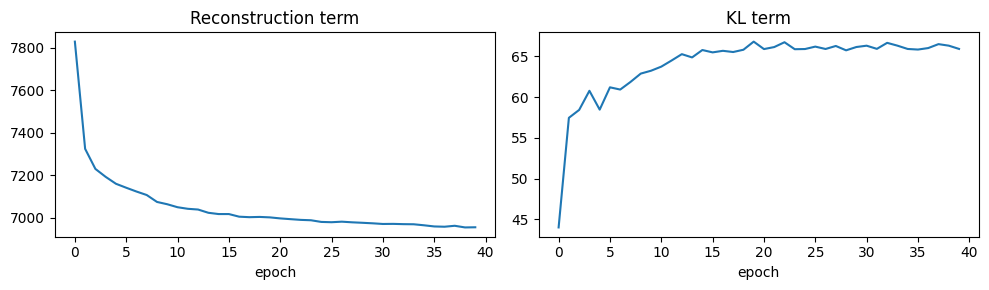

In [5]:
def train_vae(beta=1.0, n_epochs=ws.epochs(40)):
    ws.seed_everything()
    vae = ConvVAE().to(dev)
    opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
    hist, t0 = [], time.time()
    for ep in range(n_epochs):
        vae.train(); tot = rec = kl_sum = 0.0
        for x, _ in train_dl:
            x = x.to(dev)
            x_hat, mu, logvar = vae(x)
            loss, r, k = vae_loss(x_hat, x, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); rec += r.item(); kl_sum += k.item()
        hist.append((rec / len(train_dl), kl_sum / len(train_dl)))
        if (ep + 1) % 10 == 0 or ep + 1 == n_epochs:
            print(f"epoch {ep + 1}: loss {tot / len(train_dl):.1f}  recon {hist[-1][0]:.1f}  KL {hist[-1][1]:.1f}")
    return vae, hist, (time.time() - t0) / 60

vae, hist, vae_minutes = train_vae(beta=1.0)
torch.save(vae.state_dict(), os.path.join(ws.ROOT, "checkpoints", "vae_beta1.pt"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot([h[0] for h in hist]); ax[0].set_title("Reconstruction term"); ax[0].set_xlabel("epoch")
ax[1].plot([h[1] for h in hist]); ax[1].set_title("KL term"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Part B · What has the VAE learned?

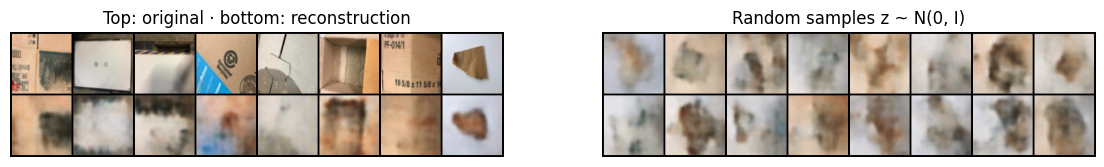

In [6]:
vae.eval()
x, _ = next(iter(val_dl))
x = x[:8].to(dev)
with torch.no_grad():
    recon = vae(x)[0]
    samples = vae.decode(torch.randn(16, LATENT, device=dev))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(make_grid(torch.cat([x, recon]).cpu(), nrow=len(x)).permute(1, 2, 0)); ax[0].set_title("Top: original · bottom: reconstruction")
ax[1].imshow(make_grid(samples.cpu(), nrow=8).permute(1, 2, 0)); ax[1].set_title("Random samples z ~ N(0, I)")
for a in ax: a.axis("off")
ws.save_figure(fig, "vae_recon_and_samples.png"); plt.show()

**TODO 4 · Interpolation.** Encode two validation images (use `mu`, not a random sample), make 10 evenly
spaced points on the straight line between their codes, decode them and show the 10 images in one row.

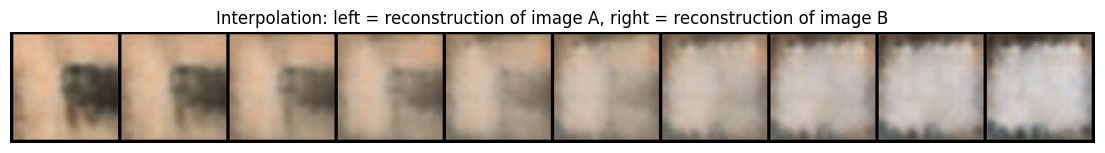

In [7]:
vae.eval()
xv, _ = next(iter(val_dl))
a, b = xv[0:1].to(dev), xv[1:2].to(dev)   # two validation images; change the indices to pick others
with torch.no_grad():
    mu_a, _ = vae.encode(a)
    mu_b, _ = vae.encode(b)
    t = torch.linspace(0, 1, 10, device=dev).view(-1, 1)
    z = (1 - t) * mu_a + t * mu_b          # 10 evenly spaced points on the line from mu_a to mu_b
    imgs = vae.decode(z).cpu()
fig = plt.figure(figsize=(14, 2))
plt.imshow(make_grid(imgs, nrow=10).permute(1, 2, 0)); plt.axis("off")
plt.title("Interpolation: left = reconstruction of image A, right = reconstruction of image B")
ws.save_figure(fig, "vae_interpolation.png"); plt.show()

## Part C · Reconstruction error as a "not recyclable" alarm
The VAE never saw trash. If trash images reconstruct worse, their error can flag them.

**TODO 5.** For every **test** image (all six classes), compute the mean squared reconstruction error per
image, using `mu` as the code (no sampling). Then compute the AUROC for separating trash (positive) from
recyclable (negative) with `sklearn.metrics.roc_auc_score`. An AUROC of 0.5 is chance; 1.0 is perfect.

AUROC trash vs recyclable: 0.404


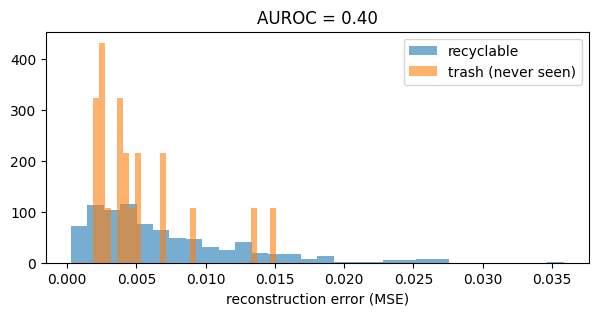

Logged: {'method': 'VAE anomaly detector', 'test_accuracy': '', 'test_macro_f1': '', 'trash_f1': '', 'local_accuracy': ''}


In [9]:
from sklearn.metrics import roc_auc_score
_, _, test_all = ws.make_loaders(img_size=IMG, batch_size=64, normalize=None)
trash_id = ws.CLASSES.index("trash")
vae.eval()
errs, labels = [], []
with torch.no_grad():
    for x, y in test_all:
        x = x.to(dev)
        mu, _ = vae.encode(x)
        x_hat = vae.decode(mu)
        errs.append(((x_hat - x) ** 2).mean(dim=(1, 2, 3)).cpu())
        labels.append(y)
errors = torch.cat(errs).numpy()
is_trash = (torch.cat(labels) == trash_id).numpy()
auroc = roc_auc_score(is_trash, errors)
print(f"AUROC trash vs recyclable: {auroc:.3f}")
fig = plt.figure(figsize=(7, 3))
plt.hist(errors[~is_trash], bins=30, alpha=0.6, density=True, label="recyclable")
plt.hist(errors[is_trash], bins=30, alpha=0.6, density=True, label="trash (never seen)")
plt.xlabel("reconstruction error (MSE)"); plt.legend(); plt.title(f"AUROC = {auroc:.2f}")
ws.save_figure(fig, "vae_anomaly_hist.png"); plt.show()

ws.log_result(3, "VAE anomaly detector", params_millions=ws.count_params(vae), train_minutes=vae_minutes,
              notes="trained on recyclables only, beta=1", auroc=float(auroc))

## Stretch
- Train with `beta=0.5` and `beta=4` (`train_vae(beta=...)`). How do samples, reconstructions and AUROC change?
- Put VAE samples next to your week-2 GAN samples. Which are sharper? Which are more varied?

## Questions for your week-3 findings note
1. Why are VAE samples blurrier than GAN samples?
2. Is reconstruction error a usable "not recyclable" alarm? Which recyclable items get falsely flagged, and why?
3. What does the interpolation show about the latent space? Would a plain autoencoder give the same picture?
4. In a real sorting line, would you rather use this detector or simply a sixth "trash" class? Give one reason each way.

epoch 10: loss 7084.9  recon 7040.1  KL 89.7
epoch 20: loss 7021.6  recon 6974.3  KL 94.6
epoch 30: loss 6994.6  recon 6947.5  KL 94.1
epoch 40: loss 6975.0  recon 6928.0  KL 94.0
beta=0.5: AUROC 0.397
epoch 10: loss 7263.9  recon 7153.7  KL 27.6
epoch 20: loss 7212.7  recon 7098.8  KL 28.5
epoch 30: loss 7186.0  recon 7071.4  KL 28.6
epoch 40: loss 7169.9  recon 7055.2  KL 28.7
beta=4.0: AUROC 0.427


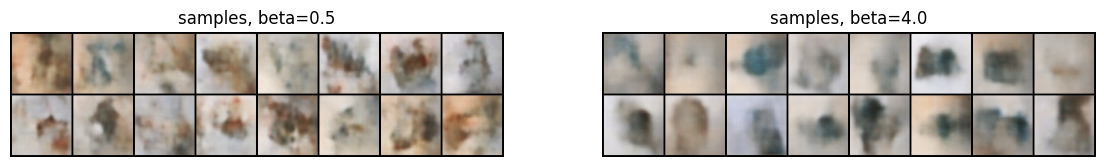

In [10]:
def anomaly_auroc(model):
    model.eval(); errs, labs = [], []
    with torch.no_grad():
        for x, y in test_all:
            x = x.to(dev); mu, _ = model.encode(x)
            errs.append(((model.decode(mu) - x) ** 2).mean(dim=(1, 2, 3)).cpu()); labs.append(y)
    e = torch.cat(errs).numpy(); t = (torch.cat(labs) == trash_id).numpy()
    return roc_auc_score(t, e)

res = {}
for b in [0.5, 4.0]:
    m, h, mins = train_vae(beta=b)
    m.eval()
    with torch.no_grad():
        s = m.decode(torch.randn(16, LATENT, device=dev)).cpu()
    res[b] = (anomaly_auroc(m), s)
    print(f"beta={b}: AUROC {res[b][0]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 3))
for a, b in zip(ax, [0.5, 4.0]):
    a.imshow(make_grid(res[b][1], nrow=8).permute(1, 2, 0)); a.set_title(f"samples, beta={b}"); a.axis("off")
plt.show()

highest-error recyclables: ['paper', 'paper', 'paper', 'paper', 'paper', 'paper', 'paper', 'paper']


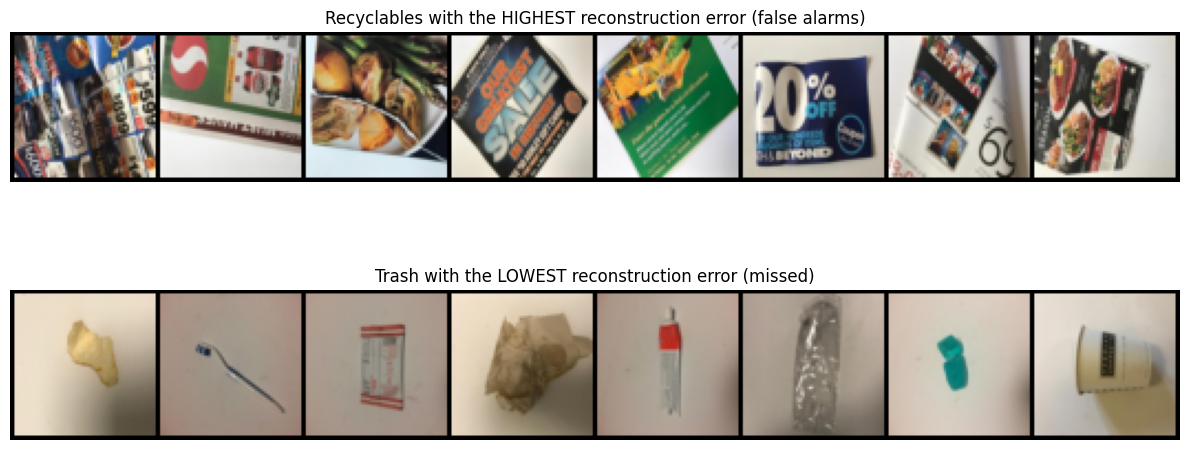

In [11]:
xs, ys = [], []
for x, y in test_all:
    xs.append(x); ys.append(y)
xs = torch.cat(xs); ys = torch.cat(ys).numpy()

rec_idx = np.where(~is_trash)[0]
worst = rec_idx[np.argsort(-errors[rec_idx])[:8]]                         # recyclables with the highest error
best_trash = np.where(is_trash)[0][np.argsort(errors[is_trash])[:8]]      # trash with the lowest error

print("highest-error recyclables:", [ws.CLASSES[i] for i in ys[worst]])
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].imshow(make_grid(xs[worst], nrow=8).permute(1, 2, 0)); ax[0].set_title("Recyclables with the HIGHEST reconstruction error (false alarms)"); ax[0].axis("off")
ax[1].imshow(make_grid(xs[best_trash], nrow=8).permute(1, 2, 0)); ax[1].set_title("Trash with the LOWEST reconstruction error (missed)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

### Stretch: effect of β
| β | Recon (epoch 40) | KL (epoch 40) | AUROC |
|---|---|---|---|
| 0.5 | 6,928 | 94.0 | 0.397 |
| 1.0 | [from my first run] | [from my first run] | 0.404 |
| 4.0 | 7,055 | 28.7 | 0.427 |

A lower β lets the codes hold more information (higher KL, slightly lower reconstruction error) and gave more colourful, varied samples. A higher β gave smoother, more uniform samples. The anomaly AUROC stayed between 0.40 and 0.43 for every β, so changing β does not fix the detector. With only 21 trash test images these small differences are within noise.

Week 3 findings note
1. Why are VAE samples blurrier than GAN samples?**
The VAE is trained to reproduce each image pixel by pixel, and the code is squeezed into only 64 numbers plus sampling noise. When the model is unsure about a detail, the pixel-wise best guess is an average of the possibilities, which looks blurry. A GAN's discriminator only asks whether an image looks real, so its generator is pushed to commit to sharp details. (I did not finish the GAN notebook, so this is a general explanation and not a comparison of my own samples.)

2. Is reconstruction error a usable "not recyclable" alarm? Which recyclable items get falsely flagged, and why?**
In my results it is not usable: the AUROC was 0.404 at β = 1 (0.397 at β = 0.5 and 0.427 at β = 4), which is no better than chance, and the histogram shows trash images with *lower* reconstruction error than many recyclables. The eight recyclable test images with the highest error were all paper: colourful magazine pages, flyers and sale ads full of bold text, logos, photos and sharp edges (and some were rotated). The trash images with the lowest error were simple, small objects (a toothbrush, a tube, foil, a paper cup, a crumpled tissue) on a plain light background. The VAE's 64-number code cannot reproduce fine detail, so reconstruction error mostly measures how visually complex an image is, not whether the item is recyclable. Only 21 trash test images were used, so the exact AUROC is uncertain, but the pattern in the images explains why it fails.

3. What does the interpolation show about the latent space? Would a plain autoencoder give the same picture?**
The ten decoded images change smoothly from the reconstruction of image A to the reconstruction of image B (the dark smudge fades and the colour shifts gradually, with no sudden jump). This means nearby points in the latent space decode to similar images, which is an effect of the KL term. A plain autoencoder has no such penalty, so its latent space can have gaps, and points between two codes may decode to unrealistic images, so I would not expect the same picture.

4. A detector or a sixth "trash" class in a real sorting line?**
In my results the sixth class is clearly better: ResNet-18 reached trash F1 0.850 in week 1, while the VAE alarm had AUROC 0.40 (worse than chance). The detector's one real advantage is that it needs no labelled trash examples and could in principle flag any unseen item, whereas a trash class needs labelled examples and may miss kinds of trash it has never seen. That advantage only matters if the detector actually works, and mine did not.